# **C12 - Black Scholes para valuar opciones asiáticas**
## **Simulación de Procesos Financieros**

---

**Autor:** Francisco Uriel Ledezma Chávez
**Carrera:** Ingeniería Financiera
**Institución:** ITESO — Universidad Jesuita de Guadalajara
**Semestre:** 5° — Simulación de Procesos Financieros
**Fecha de realización:** 14 y 18 de octubre de 2026

---

**Ejercicio:** valuar una call asiática de promedio aritmético con $S_0 = 100$, $K = 100$, $r = 5\%$, $\sigma = 20\%$ y $T = 1$ usando como variable de control la asiática de promedio geométrico, cuyo precio se obtiene con Black-Scholes ajustado, comenzando en clase con la forma cerrada y diez trayectorias y terminando con 100 trayectorias según el procedimiento del ejercicio resuelto a mano.

C11 cerró con la advertencia de que el error de Monte Carlo cae apenas con la raíz del número de simulaciones, de modo que cada decimal adicional de precisión cuesta cien veces más simulaciones, y la salida que se desarrolla aquí consiste en apoyarse en un contrato parecido cuyo precio sí se conoce, ya que la asiática aritmética carece de forma cerrada porque la suma de variables lognormales no es lognormal, mientras que la geométrica sí la tiene, y como los dos promedios de una misma trayectoria se mueven casi a la par, el error que la simulación comete al valuar la geométrica sirve para corregir la estimación de la aritmética.

## Índice de contenidos

1. Sección 1 — Forma cerrada de la asiática geométrica
2. Sección 2 — Diez trayectorias y los dos promedios
3. Sección 3 — Cien trayectorias y los pagos de ambos promedios
4. Sección 4 — Estimador con variable de control
5. Sección 5 — Reducción de varianza sobre 1,000 repeticiones
6. Sección 6 — Sesgo por monitoreo discreto
7. Sección 7 — Conclusiones

## Importación de bibliotecas

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm
from scipy.stats import gmean

np.random.seed(23)

ANCLA, ACENTO = "#1f2d3d", "#b8860b"

In [2]:
S0 = 100    # Precio inicial
k = 100     # Precio de ejercicio
std = 0.2   # Volatilidad
r = 0.05    # Tasa libre de riesgo
T = 1       # Vencimiento en años
n = 252     # Pasos de tiempo
M = 10      # Número de trayectorias

## 1. Forma cerrada de la asiática geométrica

El logaritmo del promedio geométrico de un movimiento browniano geométrico es una suma de normales, por lo cual el promedio mismo es lognormal y su opción se valúa con Black-Scholes una vez que se sustituyen dos parámetros, la volatilidad, que con promedio continuo se reduce a $\sigma/\sqrt{3}$ porque la varianza del logaritmo del promedio es un tercio de la del precio terminal, y el costo de acarreo, que pasa a ser la tasa a la que crece el valor esperado del promedio.

$$\sigma_A = \frac{\sigma}{\sqrt{3}}, \qquad q_A = \frac{1}{2}\left(r - \frac{\sigma_A^2}{2}\right)$$

$$C_G = S_0 e^{(q_A - r)T} N(d_1) - K e^{-rT} N(d_2), \qquad d_1 = \frac{\ln(S_0/K) + (q_A + \sigma_A^2/2)\,T}{\sigma_A\sqrt{T}}, \qquad d_2 = d_1 - \sigma_A\sqrt{T}$$

Las funciones `d1_d2` y `bs` reciben ese costo de acarreo en el argumento `q`, que entra en el exponente como $e^{(q - r)T}$ y no como un dividendo, de modo que con $q = r$ la misma función entrega la call europea sin dividendos, que se calcula aquí como referencia para dimensionar cuánto vale el promedio frente al precio terminal.

In [3]:
def d1_d2(S, K, r, sigma, T, q):
    d1 = (np.log(S / K) + (q + 0.5 * sigma ** 2) * T) / (sigma * np.sqrt(T))
    return d1, d1 - sigma * np.sqrt(T)


def bs(S, K, r, sigma, T, call=True, q=0):
    """Black-Scholes con costo de acarreo q; con q = r es la europea sin dividendos. Usa d1_d2."""
    d1, d2 = d1_d2(S, K, r, sigma, T, q)
    if call:
        return S * np.exp((q - r) * T) * norm.cdf(d1) - K * np.exp(-r * T) * norm.cdf(d2)
    return K * np.exp(-r * T) * norm.cdf(-d2) - S * np.exp((q - r) * T) * norm.cdf(-d1)

In [4]:
volatilidad_ajustada = std / np.sqrt(3)  # Ajuste de volatilidad para opciones asiáticas
b = r  # Costo de acarreo (carry cost) del subyacente

Costo_acarreo = 0.5 * (b - 0.5 * volatilidad_ajustada**2)

d1, d2 = d1_d2(
    S0, k, r, volatilidad_ajustada, T, q=Costo_acarreo
)

put_asiatica = bs(
    S0, k, r, sigma = volatilidad_ajustada, T = T, call=False, q=Costo_acarreo
)

call_asiatica = bs(
    S0, k, r, volatilidad_ajustada, T, call=True, q=Costo_acarreo
)

call_europea = bs(S0, k, r, std, T, call=True, q=r)

pd.Series({
    "Volatilidad ajustada": volatilidad_ajustada,
    "Costo de acarreo": Costo_acarreo,
    "d1": d1,
    "d2": d2,
    "Put asiática geométrica": put_asiatica,
    "Call asiática geométrica": call_asiatica,
    "Call europea (referencia)": call_europea,
}, name="Valor").round(4).to_frame()

,Valor
Volatilidad ajustada,0.1155
Costo de acarreo,0.0217
d1,0.2454
d2,0.1299
Put asiática geométrica,3.4633
Call asiática geométrica,5.5468
Call europea (referencia),10.4506


La volatilidad ajustada resulta de 0.1155 y el costo de acarreo de 0.0217, menos de la mitad de la tasa libre de riesgo, con lo cual la call asiática geométrica vale 5.5468 y la put 3.4633 frente a 10.4506 de la call europea con los mismos datos, de modo que la call asiática cuesta apenas el 53.1% de la europea, ya que promediar el precio a lo largo del año amortigua los extremos que dan valor a la opción, y ese precio exacto es el que hace útil a la geométrica, pues ofrece un punto de comparación conocido que la asiática aritmética no tiene.

## 2. Diez trayectorias y los dos promedios

Las trayectorias se simulan con `create_paths`, que avanza el precio en 252 pasos diarios a partir de $S_0$, y sobre la misma trayectoria se calculan después el promedio aritmético, que define el pago de `payoff_asiatica`, y el promedio geométrico, que define el de la asiática con forma cerrada, de modo que ambos contratos quedan expuestos exactamente a la misma aleatoriedad.

In [5]:
def create_paths(S0, r, std, T, n, M):
    dt = T / n
    paths = np.zeros((M, n + 1))
    paths[:, 0] = S0
    for i in range(n):
        Z = np.random.normal(0, 1, M)
        paths[:, i + 1] = paths[:, i] * np.exp((r - 0.5 * std ** 2) * dt + std * np.sqrt(dt) * Z)
    return paths

def payoff_asiatica(paths, K, call=True):
    precios_promedio = np.mean(paths, axis=1)
    if call:
        return np.maximum(precios_promedio - K, 0)
    else:
        return np.maximum(K - precios_promedio, 0)

def graf_trayectorias(paths, T=1, mostrar=50, K=None, bandas=None, titulo="Trayectorias simuladas"):
    """bandas = (t, inferior, superior), por ejemplo la salida de envolvente(...)."""
    t = np.linspace(0, T, paths.shape[1])
    plt.figure(figsize=(10, 5))
    plt.plot(t, paths[:mostrar].T, lw=0.7, alpha=0.7)
    if bandas is not None:
        plt.plot(bandas[0], bandas[1], "k--", bandas[0], bandas[2], "k--", lw=1.5)
    if K is not None:
        plt.axhline(K, color="red", ls="--", label=f"K = {K}")
        plt.legend()
    plt.title(titulo); plt.xlabel("t"); plt.ylabel("Precio"); plt.grid(alpha=0.3); plt.show()

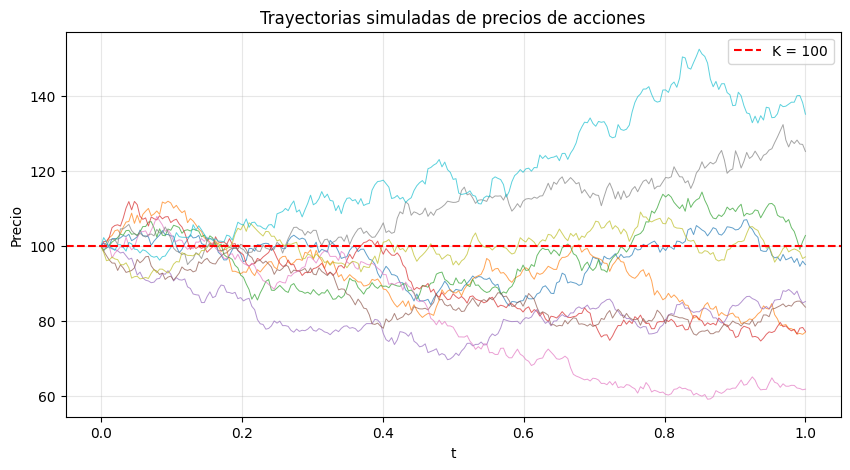

In [6]:
paths = create_paths(S0, r, std, T, n, M)
graf_trayectorias(paths, T, mostrar=10, K=k, titulo="Trayectorias simuladas de precios de acciones")

Las diez trayectorias parten de 100 y durante el primer trimestre se mantienen cerca del precio de ejercicio para después separarse, con dos de ellas que terminan claramente por encima de 120 y una que cae por debajo de 65, de modo que la muestra resulta pequeña y cargada hacia abajo, ya que siete de las diez terminan el año por debajo de la línea de $K$.

In [7]:
media_aritmetica = np.mean(paths, axis=-1)
media_geometrica = gmean(paths, axis=-1)

promedios = pd.DataFrame({
    "Precio final": paths[:, -1],
    "Promedio aritmético": media_aritmetica,
    "Promedio geométrico": media_geometrica,
    "Diferencia": media_aritmetica - media_geometrica,
}, index=pd.RangeIndex(1, M + 1, name="Trayectoria"))

promedios.round(4)

,Precio final,Promedio aritmético,Promedio geométrico,Diferencia
Trayectoria,,,,
1,95.0647,96.8532,96.6733,0.1799
2,77.0697,92.6115,92.2315,0.3800
3,102.8443,97.7497,97.3921,0.3576
4,77.2829,89.4211,88.8503,0.5708
5,85.2557,82.1980,81.9560,0.2420
6,83.7463,86.3667,86.1157,0.2510
7,61.8962,80.4104,78.8419,1.5685
8,125.2261,110.2949,109.9486,0.3464
9,97.1442,99.7979,99.7244,0.0735


La tabla muestra que el promedio aritmético supera al geométrico en las diez trayectorias, con diferencias que van de 0.0735 a 1.5685, lo cual no es casualidad sino la desigualdad entre la media aritmética y la geométrica, y el tamaño de esa brecha depende de cuánto se dispersa el precio dentro de cada trayectoria, ya que la mínima corresponde a la novena, que termina en 97.1442 tras moverse poco alrededor de 100, mientras que la máxima corresponde a la séptima, que cae hasta 61.8962 al vencimiento.

Los promedios suavizan además el precio final, como en la tercera trayectoria, que termina en 102.8443 dentro del dinero mientras que su promedio aritmético de 97.7497 la deja fuera, de modo que una call europea pagaría en ese escenario y la asiática no, y como los dos promedios de una misma trayectoria apenas se separan, todo lo que la simulación haga mal con uno lo hará casi igual con el otro.

In [8]:
desc = np.exp(-r * T)
pago_aritmetico = payoff_asiatica(paths, k)
pago_geometrico = np.maximum(media_geometrica - k, 0)

pd.DataFrame({
    "Monte Carlo": [desc * pago_aritmetico.mean(), desc * pago_geometrico.mean()],
    "Error estándar": [desc * pago_aritmetico.std(ddof=1) / np.sqrt(M), desc * pago_geometrico.std(ddof=1) / np.sqrt(M)],
    "Forma cerrada": [np.nan, call_asiatica],
}, index=["Call asiática aritmética", "Call asiática geométrica"]).round(4)

,Monte Carlo,Error estándar,Forma cerrada
Call asiática aritmética,2.8602,2.0218,NaN
Call asiática geométrica,2.7398,1.9326,5.5468


Con diez trayectorias sólo la octava y la décima terminan con promedio por encima de 100, por lo cual el precio simulado de la geométrica es de 2.7398 frente a los 5.5468 de su forma cerrada, un faltante de 2.8070 que equivale a la mitad del precio, mientras que la aritmética, de la cual no existe forma cerrada, se estima en 2.8602 con un error estándar de 2.0218, equivalente al 71% del propio precio, y como ambas estimaciones provienen de los mismos dos pagos, el error de la geométrica, que sí puede medirse, indica que la aritmética está subestimada en una magnitud parecida.

## 3. Cien trayectorias y los pagos de ambos promedios

La parte de clase dejó claro que diez trayectorias no bastan para valuar ninguno de los dos contratos, por lo cual la continuación eleva la muestra a 100 trayectorias con la misma función `create_paths`, que conserva $S_0$ como primera observación, de modo que cada promedio se calcula sobre 253 precios y ambos pagos se obtienen de la misma trayectoria, condición necesaria para que uno sirva de control del otro.

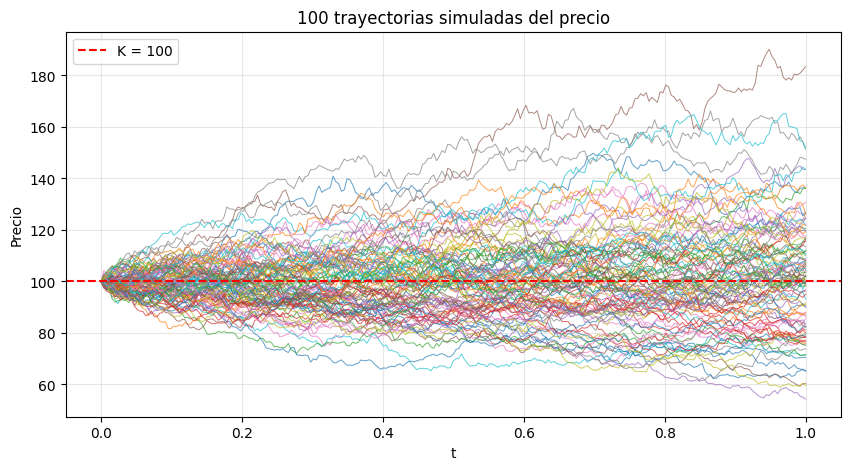

Precio al vencimiento: mínimo 54.27, máximo 183.44
Trayectorias que terminan por debajo de K: 47 de 100


In [9]:
M = 100
paths = create_paths(S0, r, std, T, n, M)
graf_trayectorias(paths, T, mostrar=M, K=k, titulo=f"{M} trayectorias simuladas del precio")

print(f"Precio al vencimiento: mínimo {paths[:, -1].min():.2f}, máximo {paths[:, -1].max():.2f}")
print(f"Trayectorias que terminan por debajo de K: {np.sum(paths[:, -1] < k)} de {M}")

Las 100 trayectorias parten de 100 y se abren en abanico conforme avanza el año, de modo que al vencimiento el precio va de 54.27 a 183.44 y 47 de ellas terminan por debajo del precio de ejercicio, aunque lo que decide el pago de la asiática no es el precio final sino el promedio del recorrido completo, que suaviza esas trayectorias extremas tal como se vio con las diez de la sección anterior.

In [10]:
media_aritmetica = np.mean(paths, axis=-1)
media_geometrica = gmean(paths, axis=-1)
pago_aritmetico = payoff_asiatica(paths, k)
pago_geometrico = np.maximum(media_geometrica - k, 0)

tabla = pd.DataFrame({
    "Promedio aritmético": media_aritmetica,
    "Promedio geométrico": media_geometrica,
    "Pago aritmético (Y)": pago_aritmetico,
    "Pago geométrico (X)": pago_geometrico,
    "(X - X̄)(Y - Ȳ)": (pago_geometrico - pago_geometrico.mean()) * (pago_aritmetico - pago_aritmetico.mean()),
    "(X - X̄)²": (pago_geometrico - pago_geometrico.mean()) ** 2,
}, index=pd.RangeIndex(1, M + 1, name="Trayectoria"))

tabla.head(10).round(4)

,Promedio aritmético,Promedio geométrico,Pago aritmético (Y),Pago geométrico (X),(X - X̄)(Y - Ȳ),(X - X̄)²
Trayectoria,,,,,,
1,128.9213,128.1981,28.9213,28.1981,520.6528,508.8849
2,91.7551,91.6087,0.0000,0.0000,32.9418,31.8050
3,106.4941,106.3912,6.4941,6.3912,0.4908,0.5649
4,95.8015,95.5445,0.0000,0.0000,32.9418,31.8050
5,79.6928,78.4494,0.0000,0.0000,32.9418,31.8050
6,104.8209,104.6864,4.8209,4.6864,0.9725,0.9085
7,81.1772,80.8211,0.0000,0.0000,32.9418,31.8050
8,88.3953,87.8822,0.0000,0.0000,32.9418,31.8050
9,107.3932,107.0336,7.3932,7.0336,2.1635,1.9433


In [11]:
print(f"Diferencia entre promedios: mínima {np.min(media_aritmetica - media_geometrica):.4f}, máxima {np.max(media_aritmetica - media_geometrica):.4f}")
print(f"Trayectorias en el dinero: aritmética {np.sum(pago_aritmetico > 0)}, geométrica {np.sum(pago_geometrico > 0)}")

Diferencia entre promedios: mínima 0.0532, máxima 2.1049
Trayectorias en el dinero: aritmética 50, geométrica 50


La tabla reproduce el formato del ejercicio hecho a mano para las primeras diez trayectorias, en las cuales los dos promedios difieren apenas en décimas, como en la primera fila, donde el aritmético es de 128.9213 y el geométrico de 128.1981, mientras que cinco de esas diez trayectorias terminan fuera del dinero en ambos promedios y aportan por ello las mismas cifras a las columnas de productos, 32.9418 y 31.8050, y en las otras cinco el pago aritmético supera al geométrico por entre 0.10 y 0.72.

Sobre las 100 trayectorias, la diferencia entre ambos promedios va de 0.0532 a 2.1049 y nunca es negativa, ya que la desigualdad entre la media aritmética y la geométrica garantiza que la primera es siempre mayor o igual, por lo cual toda trayectoria en el dinero para el promedio geométrico lo está también para el aritmético, y en esta muestra ambos contratos pagan exactamente en las mismas 50 trayectorias, sin ninguna que caiga entre los dos promedios, mientras que las otras 50 pagan cero en los dos.

## 4. Estimador con variable de control

El método del ejercicio hecho a mano parte de que el estimador estándar $\bar{Y}$ converge con probabilidad 1 al precio, aunque con un error proporcional a $1/\sqrt{M}$, y lo corrige con una variable $X$ cuyo valor esperado se conoce, que aquí es el pago geométrico de cada trayectoria, con valor esperado igual al precio de la sección 1 llevado al vencimiento, $E[X] = C_G\,e^{rT}$, mientras que $Y_i$ es el pago aritmético.

$$Y_i(b) = Y_i - b\left(X_i - E[X]\right), \qquad E\left[\bar{Y}(b)\right] = E[Y], \qquad \text{Var}\left[Y_i(b)\right] = \sigma_y^2 + b^2\sigma_x^2 - 2b\,\sigma_x\sigma_y\rho_{xy}$$

El estimador corregido es insesgado para cualquier $b$ y tiene menor varianza que el estándar siempre que $b^2\sigma_x^2 < 2b\,\sigma_x\sigma_y\rho_{xy}$, condición que en clase se escribió dividida entre $\sigma_x$ como $b^2\sigma_x < 2b\,\sigma_y\rho_{xy}$, mientras que el valor que minimiza la varianza es la pendiente de la regresión de $Y$ sobre $X$, cuyo numerador y denominador son justamente las dos últimas columnas de la tabla anterior.

$$b^* = \frac{\sigma_y}{\sigma_x}\,\rho_{xy} = \frac{\text{Cov}(X, Y)}{\text{Var}(X)} = \frac{\sum_{i=1}^{M}(X_i - \bar{X})(Y_i - \bar{Y})}{\sum_{i=1}^{M}(X_i - \bar{X})^2}, \qquad \hat{C}_{VC} = e^{-rT}\,\bar{Y}(b^*)$$

Con $b^*$ la varianza queda en $\sigma_y^2(1 - \rho_{xy}^2)$, de modo que la reducción depende sólo de la correlación entre ambos pagos, y como caso particular se reporta también $b = 1$, que equivale a sumar al precio cerrado de la geométrica la diferencia simulada entre ambos pagos.

In [12]:
b_estrella = tabla["(X - X̄)(Y - Ȳ)"].sum() / tabla["(X - X̄)²"].sum()
sigma_x = np.std(pago_geometrico, ddof=1)
sigma_y = np.std(pago_aritmetico, ddof=1)
rho = b_estrella * sigma_x / sigma_y
E_X = call_asiatica * np.exp(r * T)

print(f"b* = {tabla['(X - X̄)(Y - Ȳ)'].sum():.4f} / {tabla['(X - X̄)²'].sum():.4f} = {b_estrella:.4f}")
print(f"σx = {sigma_x:.4f}, σy = {sigma_y:.4f}, ρxy = b·σx/σy = {rho:.6f}")
print(f"Condición de clase: b²σx = {b_estrella ** 2 * sigma_x:.4f} < 2bσyρxy = {2 * b_estrella * sigma_y * rho:.4f} -> {b_estrella ** 2 * sigma_x < 2 * b_estrella * sigma_y * rho}")
print(f"La condición se cumple para 0 < b < 2b* = {2 * b_estrella:.4f}; b = 1 la cumple: {0 < 1 < 2 * b_estrella}")
print(f"Var[Y(b)] = σy² + b²σx² - 2bσxσyρxy = {sigma_y ** 2 + b_estrella ** 2 * sigma_x ** 2 - 2 * b_estrella * sigma_x * sigma_y * rho:.4f} frente a Var(Y) = σy² = {sigma_y ** 2:.4f}")
print(f"Reducción de varianza 1 / (1 - ρ²) = {1 / (1 - rho ** 2):,.1f}")
print(f"Pago geométrico esperado E[X] = {E_X:.4f}; promedio simulado X̄ = {pago_geometrico.mean():.4f}")

b* = 8408.3859 / 8143.6907 = 1.0325
σx = 9.0697, σy = 9.3668, ρxy = b·σx/σy = 0.999753
Condición de clase: b²σx = 9.6689 < 2bσyρxy = 19.3377 -> True
La condición se cumple para 0 < b < 2b* = 2.0650; b = 1 la cumple: True
Var[Y(b)] = σy² + b²σx² - 2bσxσyρxy = 0.0434 frente a Var(Y) = σy² = 87.7372
Reducción de varianza 1 / (1 - ρ²) = 2,022.2
Pago geométrico esperado E[X] = 5.8312; promedio simulado X̄ = 5.6396


El coeficiente resulta de 1.0325, el cociente de 8,408.3859 entre 8,143.6907, lo cual indica que por cada unidad que se mueve el pago geométrico el aritmético se mueve un poco más, coherente con que el promedio aritmético siempre queda por encima, y con desviaciones de 9.0697 para $X$ y 9.3668 para $Y$ la correlación que se recupera como $\rho_{xy} = b\,\sigma_x/\sigma_y$ es de 0.999753.

La condición de clase se cumple con holgura, ya que $b^2\sigma_x$ vale 9.6689 frente a 19.3377 de $2b\,\sigma_y\rho_{xy}$, aunque en $b^*$ el lado derecho es siempre exactamente el doble del izquierdo, por lo cual la comprobación dice más leída como intervalo, pues cualquier $b$ entre 0 y 2.0650 reduce la varianza, incluido el caso $b = 1$, mientras que con $b^*$ la varianza por trayectoria baja de 87.7372 a 0.0434, una reducción teórica de 2,022.2 veces.

La muestra resultó además desfavorable, como ocurrió con las diez trayectorias de clase, ya que el pago geométrico promedio fue de 5.6396 frente a un valor esperado de 5.8312, un 3.3% por debajo de lo que debería, y como ambos pagos se mueven juntos, el aritmético quedó subestimado en una proporción parecida, que es justamente el error que la variable de control detecta y corrige.

In [13]:
def valor_presente(payoffs, r, T):
    desc = np.exp(-r * T)
    return float(desc * np.mean(payoffs)), float(desc * np.std(payoffs, ddof=1) / np.sqrt(len(payoffs)))

pago_vc1 = pago_aritmetico - (pago_geometrico - E_X)
pago_vc = pago_aritmetico - b_estrella * (pago_geometrico - E_X)

df = pd.DataFrame({
    "Monte Carlo simple": valor_presente(pago_aritmetico, r, T),
    "Variable de control, b = 1": valor_presente(pago_vc1, r, T),
    "Variable de control, b*": valor_presente(pago_vc, r, T),
}, index=["Precio", "Error estándar"]).T
df["IC 95% inferior"] = df["Precio"] - 1.96 * df["Error estándar"]
df["IC 95% superior"] = df["Precio"] + 1.96 * df["Error estándar"]
df["Reducción de varianza"] = (df.loc["Monte Carlo simple", "Error estándar"] / df["Error estándar"]) ** 2
df.round(4)

,Precio,Error estándar,IC 95% inferior,IC 95% superior,Reducción de varianza
Monte Carlo simple,5.5563,0.8910,3.8099,7.3026,1.0000
"Variable de control, b = 1",5.7386,0.0343,5.6713,5.8059,673.3951
"Variable de control, b*",5.7445,0.0198,5.7056,5.7833,2022.1711


Monte Carlo simple entrega 5.5563 con un error estándar de 0.8910 y un intervalo al 95% que va de 3.8099 a 7.3026, tan amplio que no serviría para cotizar el contrato, mientras que la variable de control con $b^*$ sube el precio a 5.7445, una corrección de 0.1882 que equivale al faltante del pago geométrico, de 5.6396 frente a 5.8312, multiplicado por 1.0325 y descontado, y su error estándar cae a 0.0198, 45 veces menor, con un intervalo de 5.7056 a 5.7833 cuyo ancho de 0.0777 es apenas el 2% del anterior.

La versión con $b = 1$ también funciona, con un precio de 5.7386 y un error estándar de 0.0343, aunque su reducción de varianza de 673.4 queda lejos de las 2,022.2 de $b^*$, ya que al ignorar que el pago aritmético se mueve 3.3% más que el geométrico deja sin corregir una parte del error, y expresada en simulaciones, la reducción de $b^*$ significa que estas 100 trayectorias con control alcanzan la precisión que Monte Carlo simple obtendría con unas 202,000.

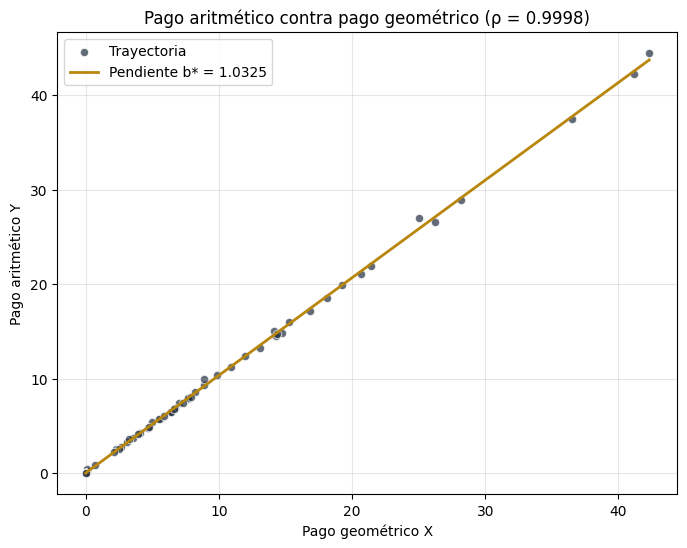

In [14]:
x = np.linspace(0, pago_geometrico.max(), 100)

plt.figure(figsize=(8, 6))
plt.scatter(pago_geometrico, pago_aritmetico, s=36, color=ANCLA, alpha=0.7, edgecolor="white", linewidth=0.8, label="Trayectoria")
plt.plot(x, pago_aritmetico.mean() + b_estrella * (x - pago_geometrico.mean()), color=ACENTO, lw=2, label=f"Pendiente b* = {b_estrella:.4f}")
plt.title(f"Pago aritmético contra pago geométrico (ρ = {rho:.4f})")
plt.xlabel("Pago geométrico X"); plt.ylabel("Pago aritmético Y")
plt.legend(); plt.grid(alpha=0.3); plt.show()

La nube de puntos es prácticamente una recta, ya que las 100 trayectorias se alinean sobre la pendiente de 1.0325 desde el origen, donde se acumulan las 50 que no pagan en ningún contrato, hasta el extremo superior, donde un pago geométrico cercano a 42 corresponde a uno aritmético cercano a 44, y esa alineación es la que hace funcionar el método, pues como el centro verdadero de la nube sobre el eje horizontal se conoce por la forma cerrada, la recta traslada ese conocimiento al eje vertical casi sin margen de error.

## 5. Reducción de varianza sobre 1,000 repeticiones

El factor de 2,022.2 de la sección anterior proviene de una correlación estimada con sólo 100 puntos, y una sola corrida no permite separar la eficacia del método de la suerte de la muestra, por lo cual `repeticion` genera 1,000 veces un conjunto nuevo de 100 trayectorias, reestima $b^*$ en cada una como se haría en la práctica y guarda los promedios de ambos pagos, de modo que la desviación estándar de los 1,000 precios resultantes mide el error estándar verdadero de cada estimador sin depender de lo que una corrida aislada diga de sí misma.

In [15]:
def repeticion(M):
    paths = create_paths(S0, r, std, T, n, M)
    pago_aritmetico = payoff_asiatica(paths, k)
    pago_geometrico = np.maximum(gmean(paths, axis=-1) - k, 0)
    b_estrella = np.cov(pago_aritmetico, pago_geometrico, ddof=1)[0, 1] / np.var(pago_geometrico, ddof=1)
    return pago_aritmetico.mean(), pago_geometrico.mean(), b_estrella

R = 1000
Y_rep, X_rep, b_rep = np.array([repeticion(M) for _ in range(R)]).T

estimaciones = pd.DataFrame({
    "Monte Carlo simple": desc * Y_rep,
    "Variable de control, b = 1": desc * (Y_rep - (X_rep - E_X)),
    "Variable de control, b*": desc * (Y_rep - b_rep * (X_rep - E_X)),
})

df_rep = pd.DataFrame({
    "Media de las estimaciones": estimaciones.mean(),
    "Desviación estándar": estimaciones.std(ddof=1),
})
df_rep["Reducción de varianza"] = (df_rep.loc["Monte Carlo simple", "Desviación estándar"] / df_rep["Desviación estándar"]) ** 2
df_rep.round(4)

,Media de las estimaciones,Desviación estándar,Reducción de varianza
Monte Carlo simple,5.7858,0.7847,1.0000
"Variable de control, b = 1",5.7651,0.0347,511.8638
"Variable de control, b*",5.7639,0.0233,1133.2981


La desviación estándar del precio cae de 0.7847 con Monte Carlo simple a 0.0347 con $b = 1$ y a 0.0233 con $b^*$, lo cual da reducciones de varianza de 511.9 y 1,133.3 veces, de modo que $b^*$ conserva una ventaja de 2.2 veces sobre $b = 1$ y confirma que estimar la pendiente vale el cálculo adicional de una covarianza.

La reducción efectiva de 1,133.3 resulta sin embargo poco más de la mitad de los 2,022.2 que anticipaba la corrida de la sección 4, porque esa muestra se equivocó en ambos sentidos, con un error estándar simple de 0.8910 por encima del típico de 0.7847 y uno controlado de 0.0198 por debajo del típico de 0.0233, de modo que el orden de magnitud se sostiene y 100 trayectorias con control equivalen a unas 113,000 sin él, aunque la cifra que debe reportarse es la de las repeticiones y no la de una corrida aislada.

Las medias de los tres estimadores son 5.7858, 5.7651 y 5.7639, y la distancia de la primera a la última, de 0.0219, no es significativa, ya que el error estándar de esa media es de 0.7847 entre $\sqrt{1000}$, cerca de 0.0248, lo cual la deja a menos de un error estándar, mientras que $b = 1$ y $b^*$ difieren en poco más de una milésima, apenas el 5% de la desviación de 0.0233 de una sola estimación, de modo que estimar $b^*$ con la misma muestra que se corrige no introduce un sesgo que importe en la práctica.

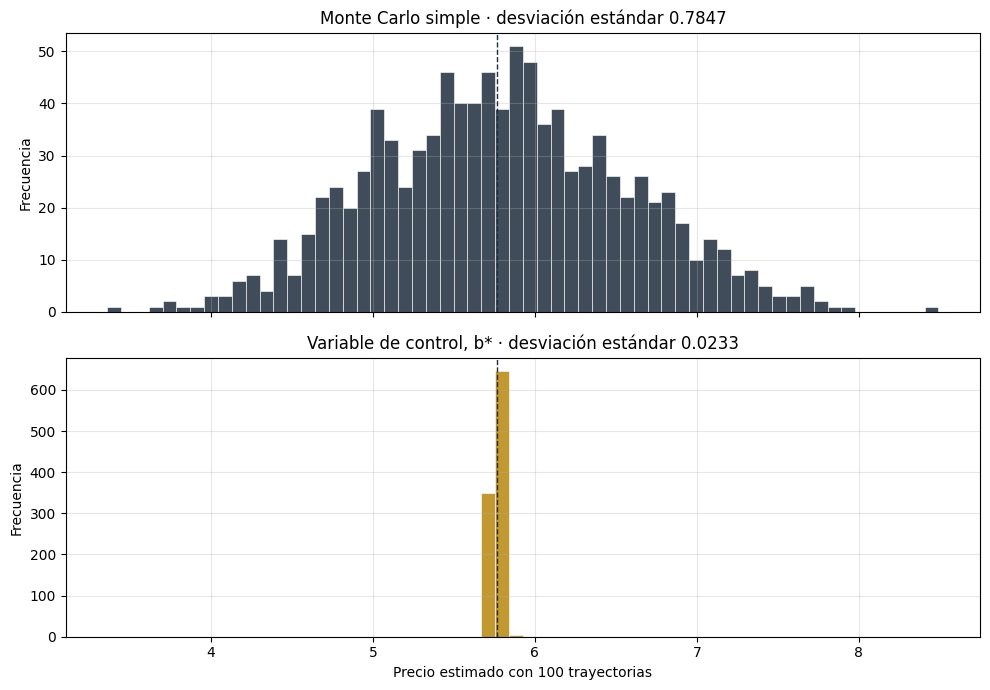

Monte Carlo simple: de 3.3595 a 8.4912
Variable de control, b*: de 5.7075 a 5.8536


In [16]:
bins = np.histogram_bin_edges(estimaciones["Monte Carlo simple"], bins=60)

fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
for ax, col, color in zip(axes, ["Monte Carlo simple", "Variable de control, b*"], [ANCLA, ACENTO]):
    ax.hist(estimaciones[col], bins=bins, color=color, alpha=0.85, edgecolor="white", linewidth=0.5)
    ax.axvline(estimaciones["Variable de control, b*"].mean(), color=ANCLA, ls="--", lw=1)
    ax.set_title(f"{col} · desviación estándar {estimaciones[col].std(ddof=1):.4f}")
    ax.set_ylabel("Frecuencia"); ax.grid(alpha=0.3)
axes[1].set_xlabel(f"Precio estimado con {M} trayectorias")
plt.tight_layout(); plt.show()

for col in ["Monte Carlo simple", "Variable de control, b*"]:
    print(f"{col}: de {estimaciones[col].min():.4f} a {estimaciones[col].max():.4f}")

El histograma hace visible la diferencia, ya que sobre el mismo eje horizontal los precios de Monte Carlo simple se reparten entre 3.3595 y 8.4912, mientras que los 1,000 precios con control caben entre 5.7075 y 5.8536, dentro de sólo tres clases del histograma y en un rango 35 veces más estrecho, y en ambos paneles la línea punteada marca la media de las estimaciones con control, sobre la cual se centra también la distribución simple, lo cual confirma que la variable de control no mueve el precio esperado sino únicamente la dispersión alrededor de él.

## 6. Sesgo por monitoreo discreto

La fórmula de clase supone que el promedio se toma de forma continua sobre todo el año, mientras que la simulación promedia 253 observaciones diarias, la primera de ellas $S_0$, que no tiene incertidumbre, y con observaciones equiespaciadas $t_i = i\,\Delta t$ el logaritmo del promedio sigue siendo normal, aunque con una varianza que se obtiene de sumar las covarianzas $\sigma^2 \min(t_i, t_j)$ entre todos los pares de observaciones.

$$\ln G = \frac{1}{n+1}\sum_{i=0}^{n} \ln S_{t_i} \sim N(\mu, v), \qquad \mu = \ln S_0 + \left(r - \frac{\sigma^2}{2}\right)\frac{T}{2}, \qquad v = \sigma^2 T\,\frac{2n+1}{6(n+1)}$$

$$C_G^{d} = e^{-rT}\left[e^{\mu + v/2} N(d_1) - K N(d_2)\right], \qquad d_1 = \frac{\mu - \ln K + v}{\sqrt{v}}, \qquad d_2 = d_1 - \sqrt{v}$$

Esa varianza tiende a $\sigma^2 T/3$ cuando $n$ crece, pero con $n = 252$ es un 0.2% menor, de 0.013307 frente a 0.013333, y el precio que corresponde a la geométrica simulada es por ello un poco más bajo, lo cual importa porque el estimador resta $b\,(\bar{X} - E[X])$, de modo que cualquier error en $E[X]$ pasa al precio multiplicado por $b$ y conviene medir cuánto pesa esa diferencia antes de dar por bueno el resultado.

In [17]:
def call_geometrica_discreta(S0, K, r, sigma, T, n):
    """Call sobre el promedio geométrico de las n + 1 observaciones, incluida la inicial."""
    mu = np.log(S0) + (r - 0.5 * sigma ** 2) * T / 2
    v = sigma ** 2 * T * (2 * n + 1) / (6 * (n + 1))
    d1 = (mu - np.log(K) + v) / np.sqrt(v)
    return np.exp(-r * T) * (np.exp(mu + 0.5 * v) * norm.cdf(d1) - K * norm.cdf(d1 - np.sqrt(v)))

call_geometrica_d = call_geometrica_discreta(S0, k, r, std, T, n)
E_X_d = call_geometrica_d * np.exp(r * T)
vc_discreta = desc * (Y_rep - b_rep * (X_rep - E_X_d))

brecha = call_asiatica - call_geometrica_d
sesgo = np.mean(b_rep) * brecha
ee_media = vc_discreta.std(ddof=1) / np.sqrt(R)

pd.Series({
    "Call geométrica, promedio continuo (clase)": call_asiatica,
    "Call geométrica, 253 observaciones diarias": call_geometrica_d,
    "Brecha entre ambas fórmulas": brecha,
    "Sesgo heredado, b* promedio × brecha": sesgo,
    "Sesgo en errores estándar de una corrida": sesgo / df.loc["Variable de control, b*", "Error estándar"],
    "Precio medio de las repeticiones, control continuo": estimaciones["Variable de control, b*"].mean(),
    "Precio medio de las repeticiones, control discreto": vc_discreta.mean(),
    "Error estándar de esa media": ee_media,
    "Sesgo en errores estándar de la media": sesgo / ee_media,
    "Corrida de la sección 4 con control discreto": valor_presente(pago_aritmetico - b_estrella * (pago_geometrico - E_X_d), r, T)[0],
}, name="Valor").round(4).to_frame()

,Valor
"Call geométrica, promedio continuo (clase)",5.5468
"Call geométrica, 253 observaciones diarias",5.5418
Brecha entre ambas fórmulas,0.0051
"Sesgo heredado, b* promedio × brecha",0.0052
Sesgo en errores estándar de una corrida,0.2644
"Precio medio de las repeticiones, control continuo",5.7639
"Precio medio de las repeticiones, control discreto",5.7586
Error estándar de esa media,0.0007
Sesgo en errores estándar de la media,7.1139
Corrida de la sección 4 con control discreto,5.7393


La call geométrica con 253 observaciones vale 5.5418 frente a los 5.5468 de la fórmula continua, una brecha de 0.0051, menos del 0.1% del precio, que la variable de control hereda multiplicada por $b^*$ como un sesgo de 0.0052 hacia arriba, y en una corrida de 100 trayectorias ese sesgo equivale a 0.26 errores estándar y queda enterrado en el ruido, por lo cual la fórmula de clase es adecuada para el ejercicio y corregirla sólo mueve el precio de la sección 4 de 5.7445 a 5.7393.

El panorama cambia al acumular las 1,000 repeticiones, ya que con 100,000 trayectorias en total el error estándar de la media baja a 0.0007 y el mismo sesgo pasa a valer 7.1 errores estándar, de modo que el precio medio de 5.7639 con el control continuo queda claramente por encima del de 5.7586 con el control discreto, y como el sesgo de una variable de control no depende del tamaño de la muestra mientras que el error estándar sí, cuanto más precisa se vuelve la simulación más importa que el valor esperado del control corresponda exactamente a la malla de tiempo simulada.

## 7. Conclusiones

La parte de clase obtuvo la forma cerrada de la asiática geométrica, 5.5468 para la call y 3.4633 para la put, con una volatilidad ajustada de 0.1155 y un costo de acarreo de 0.0217, y mostró con diez trayectorias que los dos promedios de una misma trayectoria apenas se separan, aunque la muestra era tan pequeña que la geométrica simulada se quedaba 2.8070 por debajo de su valor exacto.

La continuación convirtió esa observación en un estimador, ya que con 100 trayectorias Monte Carlo simple valúa la call asiática aritmética en 5.5563 con un error estándar de 0.8910, mientras que la variable de control geométrica la lleva a 5.7445 con un error estándar de 0.0198, y la repetición del experimento 1,000 veces confirma que la desviación del precio cae de 0.7847 a 0.0233, una reducción de varianza de 1,133.3 veces que equivale a sustituir unas 113,000 trayectorias simples por 100 controladas.

La explicación está en la correlación de 0.9998 entre ambos pagos, ya que el precio de la geométrica se conoce por forma cerrada y por ello el error que la muestra comete con ella es observable y se traslada casi completo a la aritmética, mientras que el coeficiente óptimo de 1.0325 aprovecha además que el pago aritmético se mueve algo más que el geométrico y con ello reduce la varianza 2.2 veces más que la versión simple con $b = 1$.

La consecuencia es de costo, pues C11 mostró que ganar un decimal de precisión con Monte Carlo simple exige cien veces más simulaciones, mientras que aquí la variable de control obtiene tres órdenes de magnitud en varianza a cambio de un promedio adicional por trayectoria y una fórmula cerrada, de modo que para un contrato sin solución analítica conviene buscar primero un pariente con forma cerrada y alta correlación antes que aumentar la muestra.

El primer límite del ejercicio está en que el factor de reducción estimado con una sola corrida es poco confiable, ya que la de la sección 4 anticipó 2,022.2 y la reducción efectiva fue de 1,133.3, por lo cual ese factor debe medirse sobre repeticiones y no leerse de una muestra aislada.

El segundo límite está en que la fórmula de clase supone un promedio continuo, y aunque su sesgo de 0.0052 es irrelevante con 100 trayectorias, con 100,000 ya equivale a 7.1 errores estándar, de modo que al escalar la simulación el control debe valuarse con la fórmula discreta que corresponde a la malla simulada, con la cual el mejor estimado del notebook es 5.7586 con un error estándar de 0.0007.